# Density functional theory

Companion notebook to Chapter 8 of *Quantum mechanics for many-particle
systems*.  Every number quoted in the chapter is produced here; the code is
the same as in `BookManybody/BookPrograms/chapter08/` — `dft.py` (the
functionals and the Kohn-Sham solver), `densitymatrices.py` (the one- and
two-body density matrices of Section 8.2) and `kohnsham1d.py` (the verified
self-consistent-field solver of Section 8.7).

The theme is that the local density approximation is not a black box but
something one *builds*, from a system that can be solved exactly.  We first
make precise how much of the wave function the energy actually needs — the
one-body density matrix for the kinetic energy, the pair density for the
interaction — and check every identity of that section numerically.  We then
build the functional twice: once for the three-dimensional electron gas of
Chapter 6, where the answer is analytic, and once numerically for the
one-dimensional trap of Chapters 2 and 6, so that Kohn-Sham, Hartree-Fock
and the exact answer can be compared for one and the same Hamiltonian.
Finally the Kohn-Sham loop is treated as what it is, a fixed-point
iteration, and every check a production calculation should pass is run.


In [1]:
import sys, os
import numpy as np
import matplotlib.pyplot as plt

import sys, os, glob
# the chapter programs live in BookPrograms/chapterNN; put them all on the path
for _d in sorted(glob.glob(os.path.join("..", "BookManybody",
                                        "BookPrograms", "chapter*"))):
    if _d not in sys.path:
        sys.path.insert(0, _d)
import dft
import densitymatrices
import kohnsham1d

np.set_printoptions(precision=6, suppress=True, linewidth=120)

ModuleNotFoundError: No module named 'densitymatrices'

## 1. Densities and density matrices

Before any functional, the question the chapter is organised around: how
much information about the wave function does the energy need?  For a
normalised antisymmetric state the one-body density matrix and the
ordered-pair density are

$$\rho^{(1)}(x;x') = N\!\int\! dx_2\cdots dx_N\,\Psi(x,x_2,\dots)\Psi^*(x',x_2,\dots)
  = \langle\hat\psi^\dagger(x')\hat\psi(x)\rangle,
\qquad
P(x,y) = N(N-1)\!\int\! dx_3\cdots dx_N\,|\Psi(x,y,x_3,\dots)|^2,$$

with $\mathrm{Tr}\,\rho^{(1)}=N$, $\iint P=N(N-1)$, $\int P(x,y)\,dy=(N-1)n(x)$,
and the energy is *exactly*

$$E = T[\rho^{(1)}] + \int v_{\rm ext}\,n + \tfrac12\iint v\,P .$$

For a single determinant $P = n(x)n(y) - |\rho^{(1)}(x;y)|^2$, the
interaction energy splits into Hartree plus exchange, and the exchange hole
$n_x(x,y)=-|\rho^{(1)}(x;y)|^2/n(x)$ integrates to exactly $-1$.  For a
correlated state a cumulant $\lambda$ remains.  `densitymatrices.py` checks
all of this on the trap of Chapters 2 and 6.

In [2]:
densitymatrices.demo_determinant()

1. The densities of a determinant, and their identities
The Hartree-Fock determinant of chapter 6 for N = 4 fermions in the
trap, on the 401-point grid.  Every identity of the chapter is a
number that should vanish, or a trace that should be N or N(N-1):

   int n dx                      = 4.000000000000   (N = 4)
   int int P dx dy               = 12.000000000000   (N(N-1) = 12)
   max |int P(x,y) dy - (N-1) n(x)| = 2.2e-15
   max |P(x,x)|                  = 0.0e+00
   max |gamma^2 - gamma|         = 1.8e-15
   max |int n_x(x,y) dy + 1|     = 1.1e-15   (exchange-hole sum rule, every x with n > 1e-6)

Three ways of writing the same interaction energy:
   from n and gamma:   E_H = 6.4240836707   E_x = -2.9422795525   sum = 3.4818041182
   from J and K:       E_H = 6.4240836707   E_x = -2.9422795525   sum = 3.4818041182
   from <ij|v|ij>_AS of chapter 6:                       sum = 3.4818041182
   max |J_ii - K_ii| = 2.2e-16   (every self-pair cancels)

The exchange hole around a particl

The kinetic energy needs the *off-diagonal* density matrix: a phase
$e^{i\theta(x)}$ on an orbital leaves the density unchanged and changes $T$
by $\tfrac12\int n\,(\theta')^2$.  And a one-body density matrix does not fix
the two-body one — the states $(|12\rangle\pm|34\rangle)/\sqrt2$ have the same
$\rho^{(1)}$ and opposite pair-transfer amplitudes.

In [3]:
densitymatrices.demo_kinetic()
print()
densitymatrices.demo_pair_transfer()

2. The kinetic energy needs the off-diagonal density matrix
Non-interacting N = 4: T from [d_x d_x' gamma]_(x'=x) = 3.999985,
                       T from the oscillator spectrum  = 4.000000

Multiply the ground orbital by exp(i x):
   change in the density        2.2e-16
   T before                     0.250000
   T after                      0.749998
   predicted shift (1/2) int n  0.500000
The density cannot tell the two states apart; the density matrix
can, and so can the energy.  A functional of n alone that
returned T for every state is therefore impossible -- which is
why the Hohenberg-Kohn theorem is a statement about ground states.

3. A one-body density matrix does not fix the two-body one
Two fermions in four orbitals, |Psi_pm> = (|12> pm |34>)/sqrt 2:
   D_pq for Psi_+ : diag [0.5 0.5 0.5 0.5]
   D_pq for Psi_- : diag [0.5 0.5 0.5 0.5]
   max |D_+ - D_-|                 = 0.0e+00
   <a3+ a4+ a2 a1> for Psi_+       = +0.5000
   <a3+ a4+ a2 a1> for Psi_-       = -0.5000
A on

For the exact two-particle state the decomposition
$E = T + E_H + E_x + E_\lambda$ must reproduce the full-CI energy, and does;
note that $E_\lambda$ is not the correlation energy $E_{\rm exact}-E_{\rm HF}$,
because the exact $\rho^{(1)}$ is not the Hartree-Fock projector.

In [4]:
densitymatrices.demo_cumulant()

4. The exact two-particle state: the cumulant and the energy
Full diagonalisation for N = 2 in the eight-orbital basis, then
gamma, n, P and lambda = P - [n n - |gamma|^2] on the grid:

   natural occupations           [0.999162 0.999162 0.000831 0.000831] ...
   int int P                     = 2.0000000000   (N(N-1) = 2)
   max |int lambda dy - (gamma^2 - gamma)(x;x)| = 8.7e-16
   int int lambda                = -0.0033485311   = tr(gamma^2 - gamma) = -0.0033485311

The exact energy decomposed as T + E_H + E_x + E_lambda:
   <h_0>  (from D)               = 2.0300477053
   E_H[n]                        = 1.9786407619
   E_x[gamma]                    = -1.3404293526
   E_lambda                      = -0.0090286288
   sum                           = 2.6592304859
   full CI                       = 2.6592304859

   Hartree-Fock                  = 2.6630887806
   E_exact - E_HF                = -0.0038582947
E_lambda is not the correlation energy: the exact gamma differs
from the Hartree-Fo

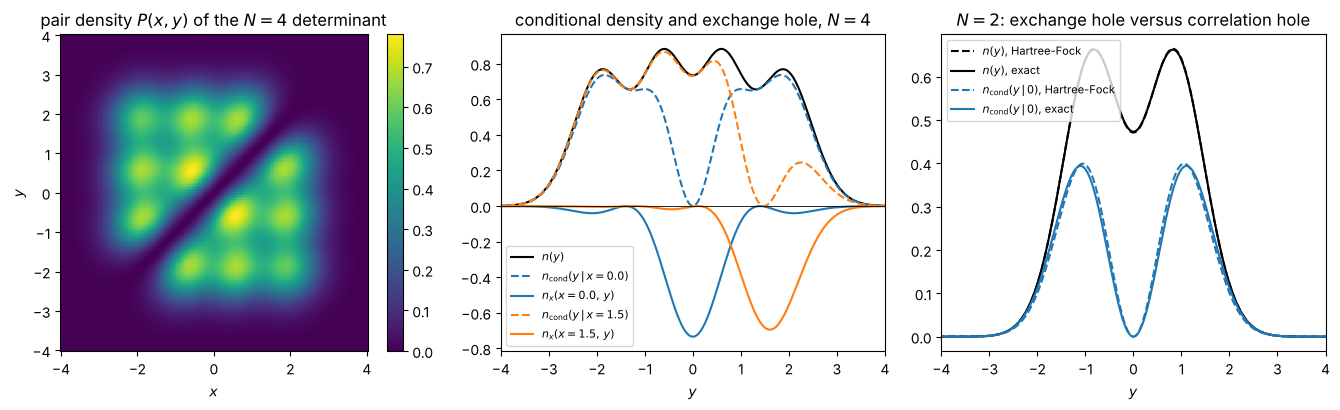

In [5]:
hf = dft.hartree_fock(4)
grid, phi = dft.oscillator_basis(8)
occ = (phi.T @ hf["C"][:, :4]).T
dd = densitymatrices.DeterminantDensities(occ, grid)

fig, ax = plt.subplots(1, 3, figsize=(13.5, 4.2))
m = np.abs(grid) <= 4.0
im = ax[0].pcolormesh(grid[m], grid[m], dd.P[np.ix_(m, m)], shading="auto")
ax[0].set_xlabel("$x$"); ax[0].set_ylabel("$y$")
ax[0].set_title("pair density $P(x,y)$ of the $N=4$ determinant")
fig.colorbar(im, ax=ax[0])

ax[1].plot(grid, dd.n, "k", label="$n(y)$")
for x0, c in ((0.0, "C0"), (1.5, "C1")):
    xj, cond = dd.conditional_density(x0)
    _, hole = dd.exchange_hole(x0)
    ax[1].plot(grid, cond, c, ls="--", label=rf"$n_{{\rm cond}}(y\,|\,x={x0})$")
    ax[1].plot(grid, hole, c, label=rf"$n_x(x={x0},\,y)$")
ax[1].axhline(0.0, color="k", lw=0.6)
ax[1].set_xlim(-4, 4); ax[1].set_xlabel("$y$")
ax[1].set_title("conditional density and exchange hole, $N=4$")
ax[1].legend(fontsize=8)

ct = densitymatrices.CorrelatedTwoParticle()
hf2 = dft.hartree_fock(2)
d2 = densitymatrices.DeterminantDensities((phi.T @ hf2["C"][:, :2]).T, grid)
j = int(np.argmin(np.abs(grid)))
ax[2].plot(grid, d2.n, "k--", label="$n(y)$, Hartree-Fock")
ax[2].plot(grid, ct.n, "k", label="$n(y)$, exact")
ax[2].plot(grid, d2.P[j] / d2.n[j], "C0--", label=r"$n_{\rm cond}(y\,|\,0)$, Hartree-Fock")
ax[2].plot(grid, ct.P[j] / ct.n[j], "C0", label=r"$n_{\rm cond}(y\,|\,0)$, exact")
ax[2].set_xlim(-4, 4); ax[2].set_xlabel("$y$")
ax[2].set_title("$N=2$: exchange hole versus correlation hole")
ax[2].legend(fontsize=8, loc="upper left")
fig.tight_layout(); plt.show()

## 2. Where the local density approximation comes from

$$E_{\rm xc}^{\rm LDA}[n] = \int d^3r\, n(\mathbf r)\,
  \epsilon_{\rm xc}\!\left(n(\mathbf r)\right),$$

with $\epsilon_{\rm xc}$ taken from the uniform gas.  For exchange the answer
is analytic,

$$\epsilon_x(n) = -\frac34\left(\frac{3}{\pi}\right)^{1/3}n^{1/3},$$

and evaluated on the uniform gas it must reproduce the $-0.916/r_s$ of
Chapter 6.  That it does is a tautology — the LDA is *defined* to be exact
there — but it is a useful check that the conventions line up.

In [6]:
dft.demo_lda_from_the_gas()

1. Where the local density approximation comes from
The exchange energy per particle of the three-dimensional gas,
   eps_x(n) = -(3/4)(3/pi)^(1/3) n^(1/3),
is the whole content of the local density approximation for
exchange.  Evaluated on the uniform gas it must reproduce the
0.916/r_s of chapter 6, and it does:

     r_s     eps_x [Ha]     eps_x [Ry]     -0.916/r_s
  1.0000      -0.458165      -0.916331      -0.916000
  2.0000      -0.229083      -0.458165      -0.458000
  4.0000      -0.114541      -0.229083      -0.229000
  4.8253      -0.094951      -0.189901      -0.189833
  6.0000      -0.076361      -0.152722      -0.152667

the coefficient itself: 0.916331
against the 0.9163 exchange coefficient of chapter 6.  This is not a
coincidence but a tautology: the LDA is *defined* so that it is
exact for the uniform gas.  What is not obvious, and what makes it
useful, is that it remains good when the density varies.

The Thomas-Fermi kinetic energy density comes from the same
calcula

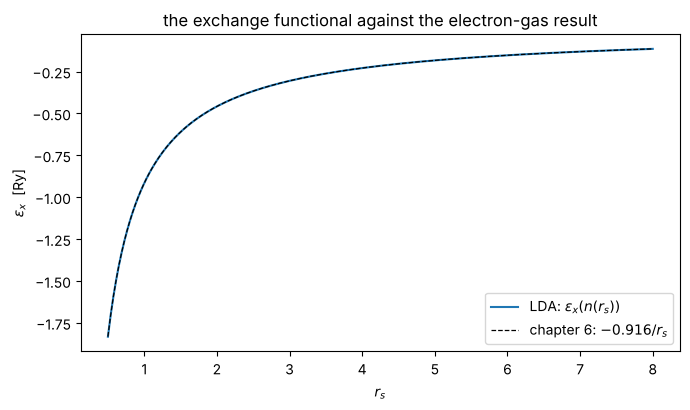

In [7]:
rs = np.linspace(0.5, 8.0, 400)
n = dft.ExchangeLDA3D.density_from_rs(rs)
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(rs, 2 * dft.ExchangeLDA3D.eps_x(n), label=r"LDA: $\epsilon_x(n(r_s))$")
ax.plot(rs, -0.916 / rs, "k--", lw=0.9, label=r"chapter 6: $-0.916/r_s$")
ax.set_xlabel(r"$r_s$"); ax.set_ylabel(r"$\epsilon_x$  [Ry]")
ax.set_title("the exchange functional against the electron-gas result")
ax.legend(); fig.tight_layout(); plt.show()

## 3. The exchange hole

Each electron moves inside a hole in the density of its neighbours.  For the
uniform gas the pair correlation function is exact at the Hartree-Fock level,

$$g(y) = 1 - \frac92\left[\frac{\sin y - y\cos y}{y^3}\right]^2,
\qquad y = k_F s,$$

with $g(0)=\tfrac12$: same-spin electrons never coincide, opposite-spin ones
are uncorrelated at this level.  The hole contains exactly one missing
electron, and that sum rule is a large part of why local functionals work at
all — the energy depends mostly on the *charge* of the hole, which is fixed
exactly, and only weakly on its shape.

In [8]:
dft.demo_exchange_hole()

2. The exchange hole
Exchange is not a mysterious correction: it is the statement that
each electron carries around it a region depleted of electrons of
the same spin.  For the uniform gas the pair correlation function
is known exactly at the Hartree-Fock level,
   g(s) = 1 - (9/2)[(sin y - y cos y)/y^3]^2,   y = k_F s.

   k_F s         g(s)   interpretation
    0.00     0.500000   g(0) = 1/2: same spins never coincide
    0.50     0.524471   
    1.00     0.591838   
    2.00     0.786732   
    4.00     0.996208   
    8.00     0.999920   
   16.00     0.999939   the hole has healed

The hole integrates to exactly one missing electron,
   n int d^3s [g(s) - 1] = (4 / 3 pi) int_0^inf dy y^2 [g(y) - 1]
                         = -1,
which is the sum rule that any decent approximate functional must
respect.  Checking it numerically:


   (4 / 3 pi) int dy y^2 [g(y) - 1] = -0.997615

The exact value of the integral is -pi/6 times 9/2, and the
prefactor turns it into exactly -1.  Local functionals are built
to satisfy this sum rule even when they get the shape of the hole
wrong, which is a large part of why they work at all.


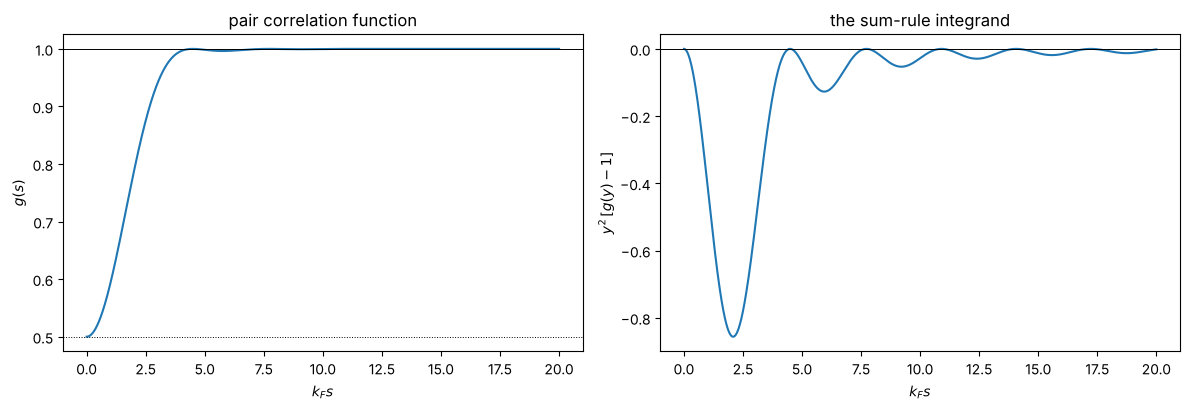

In [9]:
y = np.linspace(1e-6, 20.0, 2000)
g = dft.exchange_hole(y)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot(y, g)
ax[0].axhline(1.0, color="k", lw=0.7); ax[0].axhline(0.5, color="k", ls=":", lw=0.7)
ax[0].set_xlabel(r"$k_F s$"); ax[0].set_ylabel("$g(s)$")
ax[0].set_title("pair correlation function")
ax[1].plot(y, y**2 * (g - 1.0))
ax[1].axhline(0.0, color="k", lw=0.7)
ax[1].set_xlabel(r"$k_F s$"); ax[1].set_ylabel(r"$y^2\,[g(y)-1]$")
ax[1].set_title("the sum-rule integrand")
fig.tight_layout(); plt.show()

## 4. Building a functional for the model interaction

The trap of Chapters 2 and 6 uses a softened Coulomb interaction in one
dimension, for which no tabulated functional exists.  So we do what is done in
practice: solve the uniform gas once, tabulate, interpolate.  For a spinless
1D gas $k_F = \pi n$ and $\rho^{(1)}(s) = \sin(k_F s)/\pi s$, so

$$\epsilon_x(n) = -\frac1n\int_0^\infty ds\, v(s)
  \left[\frac{\sin(k_F s)}{\pi s}\right]^2 .$$

In [10]:
dft.demo_lda_1d()

3. Building a local functional for the model interaction
The trap of chapters 2 and 6 has a softened Coulomb interaction in
one dimension, for which no closed-form exchange functional
exists.  So we do what is done in practice: solve the uniform gas
once, tabulate, and interpolate.  For a spinless one-dimensional
gas k_F = pi n, the density matrix is sin(k_F s)/(pi s), and
   eps_x(n) = -(1/n) int_0^inf ds v(s) [sin(k_F s)/(pi s)]^2.
The integral is done in Fourier space, where the interaction
becomes 2 K_0(a|q|) and the squared density matrix a triangle of
base 2 k_F, so that both e_x(n) and its derivative v_x(n) are
finite integrals over [0, 2 k_F]; a cubic Hermite spline through
both makes the potential the exact derivative of the energy.



       n       eps_x(n)         v_x(n)
   0.050    -0.17352932    -0.29737268
   0.100    -0.27855681    -0.45906403
   0.200    -0.42332707    -0.65789093
   0.400    -0.59557953    -0.84878593
   0.800    -0.75884391    -0.96587633
   1.500    -0.86548990    -0.99703512
   2.500    -0.91895555    -0.99989688

Three checks.  The potential must be the derivative of the energy
density; the Fourier-space values must agree with a direct
real-space quadrature; and the latter, truncated at s = 400, must
show the cost of its slowly decaying 1/s^3 tail:
   max |v_x - d(n eps_x)/dn|            = 1.85e-10
   max |Fourier - real space (s <   400)| = 1.06e-06


   max |Fourier - real space (s <  4000)| = 1.05e-08
   at n = 0.05: Fourier -0.17352932, real space (s < 400) -0.17352615

The last line is worth remembering: a difference of three parts in
a million in the functional moves the N = 4 Kohn-Sham energy by
8e-6, far above the 1e-10 to which the self-consistent loop
converges.  Convergence of the loop says nothing about the
accuracy of the functional it is given.


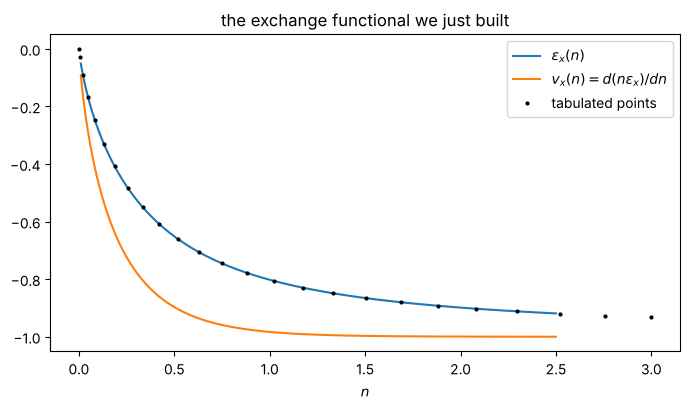

In [11]:
lda = dft.ExchangeLDA1D()
n = np.linspace(0.01, 2.5, 400)
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(n, lda.eps_x(n), label=r"$\epsilon_x(n)$")
ax.plot(n, lda.v_x(n), label=r"$v_x(n) = d(n\epsilon_x)/dn$")
ax.plot(lda.grid[::25], lda.table[::25], "k.", ms=4,
        label="tabulated points")
ax.set_xlabel("$n$"); ax.set_title("the exchange functional we just built")
ax.legend(); fig.tight_layout(); plt.show()

## 5. Solving the Kohn-Sham equations

$$\left(-\frac{\hbar^2}{2m}\nabla^2 + v_{\rm KS}(\mathbf r)\right)
  \psi_i = \varepsilon_i\psi_i,
\qquad
v_{\rm KS} = v_{\rm ext} + v_{\rm H}[n] + v_{\rm xc}[n],$$

iterated to self-consistency exactly as in Chapter 6.  Same trap, same basis
of eight oscillator orbitals, same interaction — so Kohn-Sham, Hartree-Fock
and (for two particles) the exact answer are directly comparable.

In [12]:
dft.demo_kohn_sham()

4. Solving the Kohn-Sham equations
The same trap, the same basis of eight oscillator orbitals and the
same interaction as the Hartree-Fock calculation of chapter 6, so
that the two can be compared directly.  For two particles the
exact answer is available as well.

  N    E(Kohn-Sham)   E(Hartree-Fock)     E(exact)   KS iter   HF iter
  1      0.54753706        0.50000000   0.50000000        56         2


  2      2.72023670        2.66308878   2.65923049        58        20
  3      6.45108889        6.39016133           --        58        20
  4     11.68603049       11.62305385           --        58        21

Kohn-Sham lies close to Hartree-Fock but not on top of it, and the
difference is not correlation -- we have put no correlation
functional in.  It is the error of treating exchange locally, plus
the self-interaction discussed below.


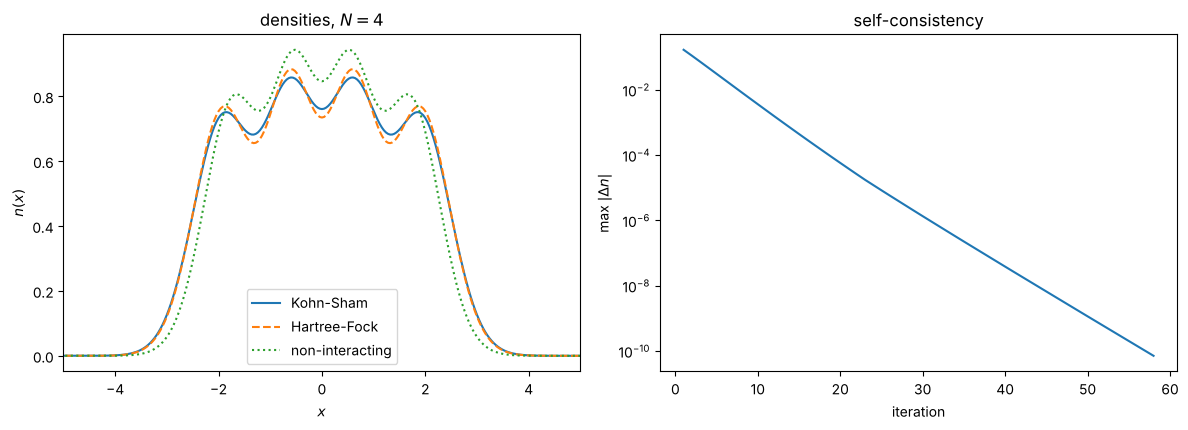

In [13]:
lda = dft.ExchangeLDA1D()
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))

ks = dft.KohnSham1D(4, lda=lda); ks.run()
hf = dft.hartree_fock(4)
grid, phi = dft.oscillator_basis(8)
n_free = (phi[:4] ** 2).sum(axis=0)
n_hf = ((phi.T @ hf["C"][:, :4]) ** 2).sum(axis=1)

ax[0].plot(grid, ks.n, label="Kohn-Sham")
ax[0].plot(grid, n_hf, "--", label="Hartree-Fock")
ax[0].plot(grid, n_free, ":", label="non-interacting")
ax[0].set_xlim(-5, 5); ax[0].set_xlabel("$x$"); ax[0].set_ylabel("$n(x)$")
ax[0].set_title("densities, $N = 4$"); ax[0].legend()

it, energies, drifts = zip(*ks.history)
ax[1].semilogy(it, drifts)
ax[1].set_xlabel("iteration"); ax[1].set_ylabel(r"max $|\Delta n|$")
ax[1].set_title("self-consistency")
fig.tight_layout(); plt.show()

## 6. The self-consistent field as a fixed-point problem

The Kohn-Sham loop solves $n_* = \mathcal F[n_*]$, where $\mathcal F$ builds
the potential from a density, diagonalises and re-forms the density.
`kohnsham1d.py` solves the same problem as `dft.KohnSham1D` a second time,
with the bookkeeping a production code needs: the sampled basis
orthogonalised with the quadrature actually used, the energy evaluated as the
*direct* functional on the output state, convergence judged on the unmixed
residual $n_{\rm out}-n_{\rm in}$, and at convergence the particle number,
the orthonormality, the orbital residual and the direct/eigenvalue energy
identity

$$E = \sum_i f_i\varepsilon_i - E_H + E_x - \int n\,v_x$$

all reported.  Two solvers that share the functional must agree at the fixed
point, and they do, to ten decimals.

In [14]:
lda = dft.ExchangeLDA1D()
kohnsham1d.demo_checks(lda)
print()
kohnsham1d.demo_two_solvers(lda)

1. One consistent output state, and what to check on it
Each row is a converged Kohn-Sham calculation in eight oscillator
functions on 401 Simpson nodes in [-8, 8], mixing 0.3.  The energy
is the direct functional on the output orbitals; the last column
is its difference from the eigenvalue formula
   E = sum_i eps_i - E_H + E_x - int n v_x,
which must vanish at self-consistency and only there.

 N         <h0>          E_H           E_x             E  iter |int n - N| |C^T C - I| |FC - C eps| |E - E_eig|
 1   0.50063452   0.60855573   -0.56165318    0.54753706    56     6.7e-16     2.2e-16      3.8e-11     3.7e-11
 2   2.02320483   1.97451757   -1.27748570    2.72023670    58     1.6e-15     4.0e-16      5.8e-11     7.7e-11
 4   8.13378445   6.42090538   -2.86865934   11.68603049    58     1.8e-15     4.8e-16      5.6e-11     1.1e-10

For N = 4 the final density residual is 7.08e-11
and the density at the edge of the box is 1.6e-21, so the box is large enough.

2. Two implementations,

 3     6.4510888925     6.4510888925      2.9e-11
 4    11.6860304874    11.6860304873      3.3e-11

The agreement is to ten decimals.  The fifth-decimal differences
between earlier editions of these tables came entirely from the
exchange table -- a real-space quadrature truncated at s = 400 --
and not from the solvers (see demo 3 of dft.py).


A tiny residual is not a converged representation.  Refining the grid, the
box and the exchange table changes nothing at $10^{-11}$; the basis is the
only representation error that matters here, and no test of this kind says
anything about the functional itself.

In [15]:
kohnsham1d.demo_representation(lda)

3. A tiny residual is not a converged representation
Every calculation below converges to a density residual below
1e-10.  Only the basis changes the energy at a visible level:



setting                                                      E   E - E_base  iter
M = 8,  401 nodes, [-8, 8]                       11.6860304873           --    58
M = 8,  801 nodes, [-8, 8]                       11.6860304873     2.51e-12    58
M = 8,  501 nodes, [-10, 10]                     11.6860304873     1.62e-13    58
M = 12, 501 nodes, [-10, 10]                     11.6853429697    -6.88e-04    58
M = 16, 501 nodes, [-10, 10]                     11.6852955478    -7.35e-04    59
M = 8,  401 nodes, broadened start               11.6860304873    -5.33e-15    63
M = 8,  401 nodes, 1201-point exchange table     11.6860304873    -2.18e-11    58

Doubling the grid, enlarging the box and doubling the exchange
table all move the energy by 1e-11 or less; going from eight to
sixteen basis functions moves it by 7e-4.  The self-consistent
loop cannot repair a basis-truncation error, and none of these
tests says anything about the error of the functional itself.


Linear mixing $n \leftarrow (1-\alpha)n + \alpha\mathcal F[n]$ converges at
the rate set by the spectral radius of $(1-\alpha)I + \alpha J$,
$J=\delta\mathcal F/\delta n$.  We build $J$ by finite differences at the
converged density, split its eigenvectors by parity (the density is even and
stays even), and compare the prediction with the measured slopes.

In [16]:
kohnsham1d.demo_mixing(lda)
print()
kohnsham1d.demo_derivative_and_one_particle(lda)

4. Linear mixing as a contraction
Near the fixed point the iteration n_{k+1} = (1 - alpha) n_k +
alpha F[n_k] has the linearised map (1 - alpha) I + alpha J,
J = dF/dn, and converges when its spectral radius is below one.
We build J by finite differences at the converged N = 4 density
and compare its prediction with the measured decay of the
residual:



   J has 14 eigenvalues above 1e-8 in modulus (its rank is at most N (M - N) = 16).
   even eigenvectors: [-0.2074 -0.0648 -0.0126  0.      0.      0.0026  0.0336]
   odd eigenvectors:  [-0.3607 -0.1107 -0.0246 -0.0025  0.      0.      0.0401]
   The density is even and stays even, so only the even sector
   is excited; the prediction below uses it alone.

 alpha  iterations  measured rate  predicted
  0.10         190         0.9016     0.9034
  0.30          58         0.7061     0.7101
  0.50          31         0.5112     0.5168
  0.70          19         0.3180     0.3235
  0.90          11         0.1170     0.1303
  1.00          15         0.2074     0.2074

The response is dominated by negative eigenvalues -- more density
in means less density out, as it must for a repulsion -- and the
rate (1 - alpha) + alpha lambda falls with alpha until the most
negative eigenvalue takes over.  The optimum, where the two ends
of the spectrum have equal and opposite rates, is alpha = 0.92
wi

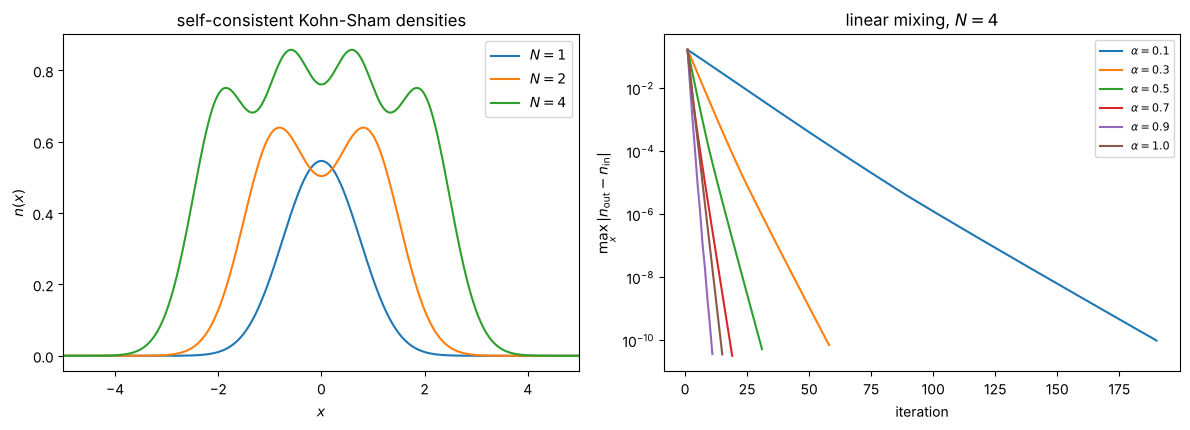

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
for N in (1, 2, 4):
    ks = kohnsham1d.KohnShamSCF(N, lda=lda); ks.solve()
    ax[0].plot(ks.x, ks.n, label=f"$N={N}$")
ax[0].set_xlim(-5, 5); ax[0].set_xlabel("$x$"); ax[0].set_ylabel("$n(x)$")
ax[0].set_title("self-consistent Kohn-Sham densities"); ax[0].legend()

for alpha, iterations, rate, history in kohnsham1d.mixing_study(lda=lda):
    ax[1].semilogy([h["iteration"] for h in history],
                   [h["residual_max"] for h in history],
                   label=rf"$\alpha={alpha}$")
ax[1].set_xlabel("iteration"); ax[1].set_ylabel(r"$\max_x|n_{\rm out}-n_{\rm in}|$")
ax[1].set_title("linear mixing, $N=4$"); ax[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

## 7. The self-interaction error

For one particle there is nothing to interact with, so the exact energy is the
oscillator ground state, $0.5$.  Hartree-Fock gets this identically right —
the direct and exchange terms cancel term by term.  A local functional cannot,
because it sees only the density, and the density of one electron is
indistinguishable from the density of half of two.

In [18]:
dft.demo_self_interaction()

5. The self-interaction error
For one particle there is nothing to interact with, so the exact
energy is the oscillator ground state, 0.5.  Hartree-Fock gets
this right identically: the direct and exchange terms cancel term
by term.  A local exchange functional cannot, because it knows
only the density, and the density of one electron looks exactly
like the density of half of two.

   exact                     0.50000000
   Hartree-Fock              0.50000000
   Kohn-Sham (LDA x)         0.54753706

   the Kohn-Sham pieces:
      Hartree energy         0.60855573
      exchange energy       -0.56165318
      sum                    0.04690255   (should vanish)
      particle number        1.00000000

The residue is the self-interaction error.  It is the reason plain
LDA overbinds anions, underestimates barriers and gives band gaps
that are too small, and it is what self-interaction corrections and
hybrid functionals -- which put back a fraction of exact exchange --
are designed to remo

The residue is what makes plain LDA overbind anions, underestimate reaction
barriers and give band gaps that are too small: an electron is spuriously
repelled by itself and spreads out to reduce that repulsion.  Removing it is
the business of self-interaction corrections and of hybrid functionals, which
mix back a fraction of exact exchange.

## 8. How good is the local approximation?

We can isolate the error of *locality* alone by evaluating, on one and the
same density, both the exact exchange energy of the determinant and the local
estimate.

In [19]:
dft.demo_local_approximation()

6. How good is the local approximation?
We can isolate the error of locality by comparing, on the *same*
density, the exact exchange energy of a determinant with the local
estimate.  Take the Kohn-Sham orbitals, compute both, and look at
the ratio.



  N     E_x (exact)       E_x (LDA)     ratio
  1     -0.60855573     -0.56165318    0.9229
  2     -1.33077759     -1.27748570    0.9600
  3     -2.11087487     -2.05547686    0.9738
  4     -2.92523832     -2.86865934    0.9807

The local approximation recovers most of the exchange energy, and
it recovers more of it as the particle number grows: the ratio
climbs from 0.92 to 0.98 between one and four particles.  That is
exactly what the construction promises -- the density becomes
smoother on the scale of the local Fermi wavelength, so the
uniform-gas estimate becomes more appropriate.  For one particle
it is worst, because there the exchange energy is nothing but the
cancellation of a spurious self-interaction.  In three dimensions
the corresponding ratio is close to 0.9 for atoms, which is why
gradient corrections were introduced.


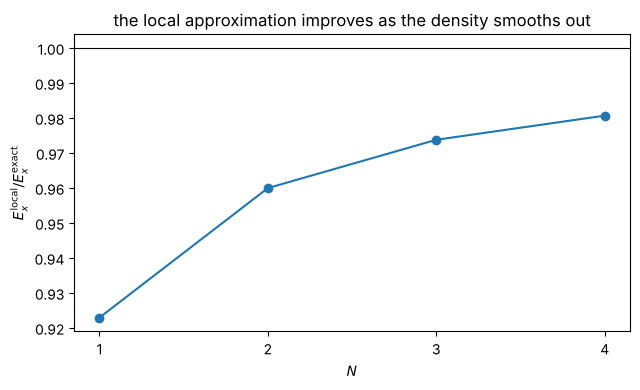

In [20]:
Ns = [1, 2, 3, 4]
ratios = []
for N in Ns:
    ks = dft.KohnSham1D(N, lda=lda); ks.run()
    vbar = dft.trap_two_body(8)
    occ = ks.C[:, :N]
    both = 0.5 * np.einsum("ai,bj,abcd,ci,dj->", occ, occ, vbar, occ, occ)
    exact_x = both - ks.hartree_energy(ks.n)
    ratios.append(ks.exchange_energy(ks.n) / exact_x)

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(Ns, ratios, "o-")
ax.axhline(1.0, color="k", lw=0.8)
ax.set_xticks(Ns); ax.set_xlabel("$N$")
ax.set_ylabel(r"$E_x^{\rm local} / E_x^{\rm exact}$")
ax.set_title("the local approximation improves as the density smooths out")
fig.tight_layout(); plt.show()

## 9. Thomas-Fermi, and why orbitals came back

Thomas-Fermi applies the local approximation to the kinetic energy as well,
which removes orbitals entirely and leaves an algebraic equation for $n(x)$.
It is enormously cheaper — and it fails, not mainly in magnitude but in
structure: the density it produces has no shells at all, and Teller proved
that within the model no molecule is bound.  The Kohn-Sham construction exists
precisely to avoid this, by keeping orbitals for the one term that a local
approximation handles badly.

In [21]:
dft.demo_thomas_fermi()

7. Thomas-Fermi, and why orbitals came back
The Thomas-Fermi model applies the local approximation to the
kinetic energy as well.  For the one-dimensional trap the kinetic
density is t[n] = (pi^2/6) n^3, and minimising
   E[n] = int dx {t[n] + x^2 n / 2} + E_H[n] + E_x[n]
gives an algebraic equation for n(x) with no orbitals at all.

The trouble is visible already for non-interacting particles,
where the exact kinetic energy is known:
  N    T (exact)   T (Thomas-Fermi)     ratio
  1     0.250000           0.302300    1.2092
  2     1.000000           1.074844    1.0748
  3     2.250000           2.340025    1.0400
  4     4.000000           4.101805    1.0255
  6     9.000000           9.120038    1.0133
  8    16.000000          16.134286    1.0084

Thomas-Fermi overshoots, badly for one particle and by less than
one per cent by eight, approaching the exact value from above as
the density smooths out.  But the error in magnitude is not the
real problem.  What the model misses is stru

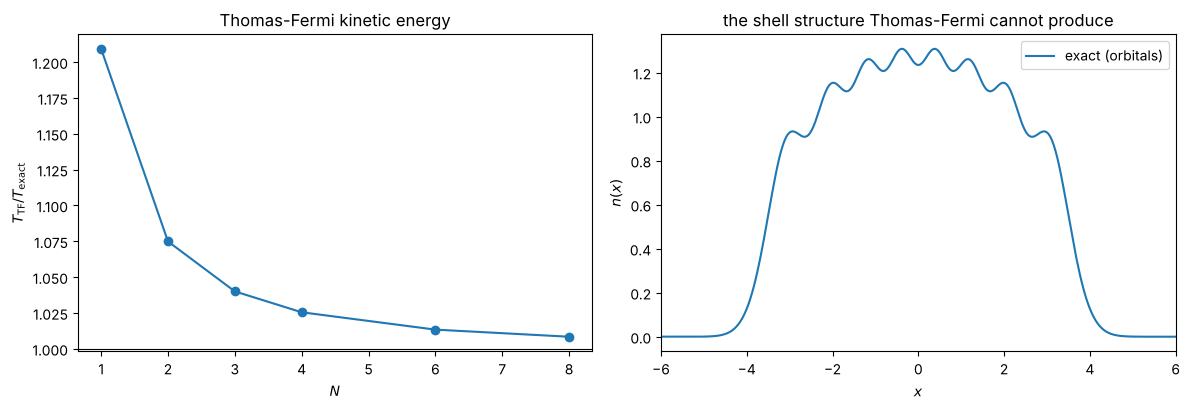

In [22]:
grid, phi = dft.oscillator_basis(8)
dx = grid[1] - grid[0]
Ns = np.array([1, 2, 3, 4, 6, 8])
ratio = []
for N in Ns:
    n = (phi[:N] ** 2).sum(axis=0)
    exact = sum(k + 0.5 for k in range(N)) - 0.5 * float(n @ grid**2) * dx
    ratio.append(float(dft.ThomasFermi.kinetic_density(n).sum()) * dx / exact)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot(Ns, ratio, "o-")
ax[0].axhline(1.0, color="k", lw=0.8)
ax[0].set_xlabel("$N$"); ax[0].set_ylabel(r"$T_{\rm TF} / T_{\rm exact}$")
ax[0].set_title("Thomas-Fermi kinetic energy")

n8 = (phi[:8] ** 2).sum(axis=0)
ax[1].plot(grid, n8, label="exact (orbitals)")
ax[1].set_xlim(-6, 6); ax[1].set_xlabel("$x$"); ax[1].set_ylabel("$n(x)$")
ax[1].set_title("the shell structure Thomas-Fermi cannot produce")
ax[1].legend()
fig.tight_layout(); plt.show()

## The full programs

Everything above lives in `BookManybody/BookPrograms/chapter08/`: `dft.py`
runs as a script and prints the seven demonstrations of the functional and
the Kohn-Sham solver, `densitymatrices.py` the four of Section 1, and
`kohnsham1d.py` the five of Section 6.  The first is printed below.

In [23]:
print(open(dft.__file__).read())

"""
Density functional theory: densities, functionals and the Kohn-Sham equations.

Companion code to chapter 8 of *Quantum mechanics for Many-particle Systems*.

Three things are done here.

First, the local density approximation is *derived* rather than quoted.  For
the three-dimensional electron gas the exchange energy per particle is
obtained from the one-body density matrix of the filled Fermi sea and checked
against the analytic 0.916/r_s of chapter 6.  The same construction is then
carried out numerically for a one-dimensional gas interacting through the
softened Coulomb potential used in chapters 2 and 6, which produces a
tabulated exchange functional for exactly that system.

Second, the Kohn-Sham equations are solved self-consistently in the same
oscillator basis as the Hartree-Fock calculation of chapter 6, so that
Hartree-Fock, Kohn-Sham and (for two particles) the exact answer can be
compared for one and the same Hamiltonian.

Third, the two characteristic errors of the lo